In [23]:
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

In [24]:
load_dotenv()

True

In [25]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0
)

In [26]:
loader = PyPDFLoader("intro-to-ml.pdf")
docs = loader.load()

In [27]:
len(docs)

392

In [28]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [29]:
len(chunks)

973

In [30]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)

print(embeddings.model)

gemini-embedding-001


In [31]:
result = embeddings.embed_query("Hello, this is a test.")

print(len(result))

3072


In [32]:
test_chunks = chunks[:20]

vector_store = FAISS.from_documents(
    test_chunks,
    embeddings
)

In [33]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [34]:
@tool
def rag_tool(query):

    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual / conceptual questions
    that might be answered from the stored documents.
    """
    result = retriever.invoke(query)

    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]

    return {
        'query': query,
        'context': context,
        'metadata': metadata
    }

In [35]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [36]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [37]:
def chat_node(state: ChatState):

    messages = state['messages']

    response = llm_with_tools.invoke(messages)

    return {'messages': [response]}

In [38]:
tool_node = ToolNode(tools)

In [39]:
graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

chatbot = graph.compile()

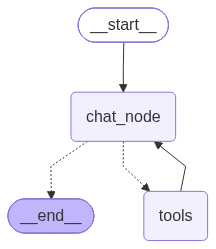

In [40]:
chatbot

In [41]:
result = chatbot.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Using the pdf notes, explain how to find the ideal value of K in KNN"
                )
            )
        ]
    }
)

In [42]:
print(result['messages'][-1].content)

[{'type': 'text', 'text': ',metadata:[{author:'}, {'type': 'text', 'text': 'Andreas C. Müller and Sarah Guido'}, {'type': 'text', 'text': ',creationdate:'}, {'type': 'text', 'text': '2016-09-21T13:04:39+00:00'}, {'type': 'text', 'text': ',creator:'}, {'type': 'text', 'text': 'AH CSS Formatter V6.2 MR4 for Linux64 : 6.2.6.18551 (2014/09/24 15:00JST)'}, {'type': 'text', 'text': ',moddate:'}, {'type': 'text', 'text': '2020-08-19T07:09:16+02:00'}, {'type': 'text', 'text': ',page:4,page_label:'}, {'type': 'text', 'text': 'iii'}, {'type': 'text', 'text': ',producer:'}, {'type': 'text', 'text': '3-Heights(TM) PDF Optimization Shell 5.9.1.5 (http://www.pdf-tools.com)'}, {'type': 'text', 'text': ',source:'}, {'type': 'text', 'text': 'intro-to-ml.pdf'}, {'type': 'text', 'text': ',title:'}, {'type': 'text', 'text': 'Introduction to Machine Learning with Python'}, {'type': 'text', 'text': ',total_pages:392,trapped:'}, {'type': 'text', 'text': '/False'}, {'type': 'text', 'text': '},{author:'}, {'t